In [28]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [29]:
import numpy as np
from mytools.halo_new import get_coord, get_mask_sector, get_mask_square, generate_local_noise_weights
from mytools.plot import plot_heatmap, plot_stack_fit_res, plot_axlines, plot_hist, plot_line_diff, make_figure, set_ticks, plt
from crafts_stack.halo_fitting import halofit, cov_to_err_map
from crafts_stack.halo_models import build_model, apply_prior
from astropy.stats import sigma_clip

<Axes: title={'center': 'Test'}, xlabel='X', ylabel='Y'>

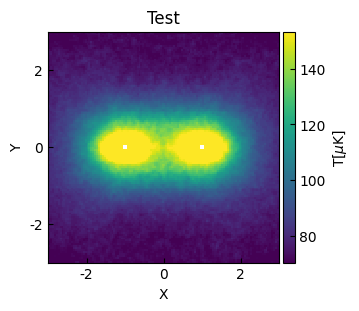

In [30]:
# data = np.load('../data/tng_pairstack_result_cube.npz', 'r')['data']
data = np.load('../data/tng_pairstack_result_hpmap.npz', 'r')['data']
# data = np.load('../data/crafts_pairstack_result_airpls.npz', 'r')['data']

data = sigma_clip(data, sigma=10, masked=True)
plot_heatmap(data, title='Test')

In [31]:
model = build_model('nfw') + build_model('gaussian', 'const')
print(model)

Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2] + [3] + [4]
Components: 
    [0]: <NFW2D(amplitude=50., x_mean=-1., y_mean=0., r_s=0.5, ellipticity=0., theta=0.)>

    [1]: <NFW2D(amplitude=50., x_mean=1., y_mean=0., r_s=0.5, ellipticity=0., theta=0.)>

    [2]: <Gaussian2D(amplitude=50., x_mean=-1., y_mean=0., x_stddev=0.5, y_stddev=0.5, theta=0.)>

    [3]: <Gaussian2D(amplitude=50., x_mean=1., y_mean=0., x_stddev=0.5, y_stddev=0.5, theta=0.)>

    [4]: <Const2D(amplitude=0.)>
Parameters:
    amplitude_0 x_mean_0 y_mean_0 r_s_0 ... y_stddev_3 theta_3 amplitude_4
    ----------- -------- -------- ----- ... ---------- ------- -----------
           50.0     -1.0      0.0   0.5 ...        0.5     0.0         0.0


In [32]:
model.param_names

('amplitude_0',
 'x_mean_0',
 'y_mean_0',
 'r_s_0',
 'ellipticity_0',
 'theta_0',
 'amplitude_1',
 'x_mean_1',
 'y_mean_1',
 'r_s_1',
 'ellipticity_1',
 'theta_1',
 'amplitude_2',
 'x_mean_2',
 'y_mean_2',
 'x_stddev_2',
 'y_stddev_2',
 'theta_2',
 'amplitude_3',
 'x_mean_3',
 'y_mean_3',
 'x_stddev_3',
 'y_stddev_3',
 'theta_3',
 'amplitude_4')

In [33]:
coord = get_coord()


tolenrance = 0.1

bounds = {
    # 'amplitude_0': (0, 200),
    # 'amplitude_1': (0, 200),
    # 'x_mean_0': (-1 - tolenrance, -1 + tolenrance),
    # 'x_mean_1': (1 - tolenrance, 1 + tolenrance),
    # 'y_mean_0': (0 - tolenrance, 0 + tolenrance),
    # 'y_mean_1': (0 - tolenrance, 0 + tolenrance),
    # 'ellipticity_0': (0, 0.5),
    # 'ellipticity_1': (0, 0.5),
    # 'theta_0': (0, 10),
    # 'theta_1': (0, 10),
    # 'r_s_0': (0.1, 10),
    # 'r_s_1': (0.1, 10),
}

constraints = {
    # "fixed": ['ellipticity_0', 'ellipticity_1'],
    "fixed": ['x_mean_0', 'y_mean_0', 'x_mean_1', 'y_mean_1','x_mean_2', 'y_mean_2', 'x_mean_3', 'y_mean_3'], # fix the center of the two NFW profiles
    "tied": [
        # ("amplitude_1", "amplitude_0"),  # amplitude_1 = amplitude_0
        # ("ellipticity_1", "ellipticity_0"),
        # ("r_s_1", "r_s_2"),
        # ('c0_0_2', 'c0_0_3'),  
        # ('c1_0_2', 'c1_0_3'),  
        # ('c2_0_2', 'c2_0_3'), 
        # ('c0_1_2', 'c0_1_3'),
        # ('c0_2_2', 'c0_2_3'),
        # ('c1_1_2', 'c1_1_3'),
    ]
}

model = apply_prior(model, bounds=bounds, constraints=constraints)
print(model.tied)
print(model.fixed)

{'amplitude_0': False, 'x_mean_0': False, 'y_mean_0': False, 'r_s_0': False, 'ellipticity_0': False, 'theta_0': False, 'amplitude_1': False, 'x_mean_1': False, 'y_mean_1': False, 'r_s_1': False, 'ellipticity_1': False, 'theta_1': False, 'amplitude_2': False, 'x_mean_2': False, 'y_mean_2': False, 'x_stddev_2': False, 'y_stddev_2': False, 'theta_2': False, 'amplitude_3': False, 'x_mean_3': False, 'y_mean_3': False, 'x_stddev_3': False, 'y_stddev_3': False, 'theta_3': False, 'amplitude_4': False}
{'amplitude_0': False, 'x_mean_0': True, 'y_mean_0': True, 'r_s_0': False, 'ellipticity_0': False, 'theta_0': False, 'amplitude_1': False, 'x_mean_1': True, 'y_mean_1': True, 'r_s_1': False, 'ellipticity_1': False, 'theta_1': False, 'amplitude_2': False, 'x_mean_2': True, 'y_mean_2': True, 'x_stddev_2': False, 'y_stddev_2': False, 'theta_2': False, 'amplitude_3': False, 'x_mean_3': True, 'y_mean_3': True, 'x_stddev_3': False, 'y_stddev_3': False, 'theta_3': False, 'amplitude_4': False}


# without mask

In [34]:
data_list, fit_model, fit_info = halofit(coord, data, model=model, print_model=True)


Fitted double NFW model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2] + [3] + [4]
Components: 
    [0]: <NFW2D(amplitude=49.48135582, x_mean=-1., y_mean=0., r_s=0.58997333, ellipticity=0., theta=-132.04200206)>

    [1]: <NFW2D(amplitude=49.48292328, x_mean=1., y_mean=0., r_s=0.58511304, ellipticity=0., theta=109.5357303)>

    [2]: <Gaussian2D(amplitude=44.8791631, x_mean=-1., y_mean=0., x_stddev=1.15942468, y_stddev=1.07184042, theta=-21.96356342)>

    [3]: <Gaussian2D(amplitude=43.55944966, x_mean=1., y_mean=0., x_stddev=1.15841627, y_stddev=1.05698708, theta=-20.47922969)>

    [4]: <Const2D(amplitude=70.43729127)>
Parameters:
      amplitude_0    x_mean_0 y_mean_0 ...       theta_3          amplitude_4   
    ---------------- -------- -------- ... ------------------- -----------------
    49.4813558151791     -1.0      0.0 ... -20.479229688721432 70.43729126513911

Goodness of fit:
Chi-squared: 983560.434
Reduced chi-squar

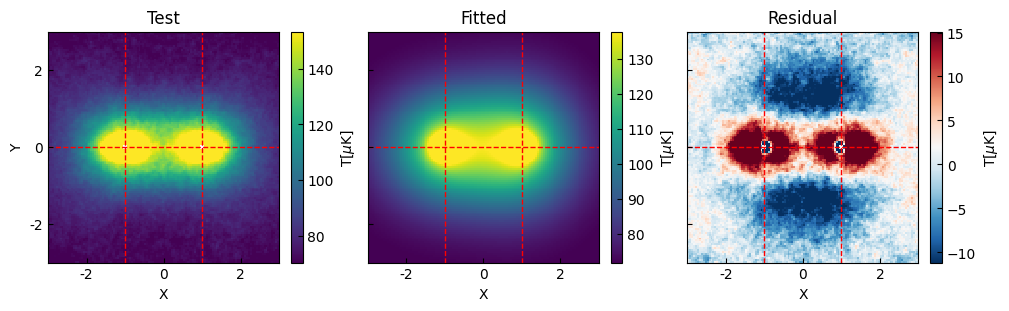

In [35]:
title = ['Test', 'Fitted', 'Residual']
axes =  plot_stack_fit_res(data_list, title=title)
# axes =  plot_stack_fit_res(data_list, title=title, vmax=[140,140, 20], vmin=[60, 60, -20])
plot_axlines(ax=axes, vl=[40, 80], hl=[60])

/home/dyliu/code/crafts_stack/src/crafts_stack/halo_fitting.py:212: RuntimeWarning: covariance is not symmetric positive-semidefinite.
  free_param_samples = rng.multivariate_normal(p_free_best, cov, size=n_samples)


<Axes: title={'center': 'Error Map'}, xlabel='X', ylabel='Y'>

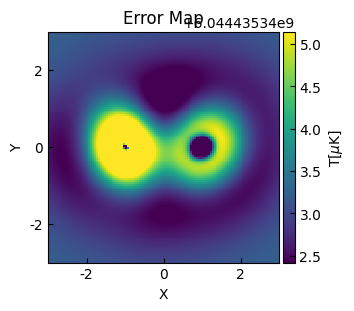

In [36]:
error_map = cov_to_err_map(fit_model, fit_info, *coord)
plot_heatmap(error_map, title='Error Map') 

# with mask sector 

<Axes: title={'center': 'Mask'}, xlabel='X', ylabel='Y'>

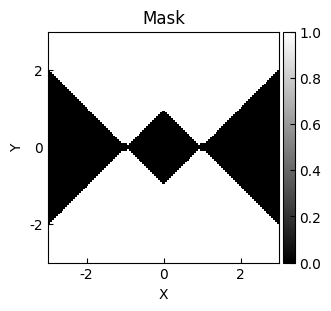

In [37]:
# mask_sector = get_mask_sector(coord=coord)
mask_sector = get_mask_sector(rlim=[0.1,5], coord=coord)
# mask_sector = get_mask_sector(thetalim=[-np.pi/3, np.pi/3], coord=coord)
plot_heatmap(mask_sector, title='Mask', cmap='gray', cbar_label='')

In [38]:
data_list_sector, fit_model, fit_info = halofit(coord, data, model=model, mask=mask_sector, print_model=True)


Fitted double NFW model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2] + [3] + [4]
Components: 
    [0]: <NFW2D(amplitude=8.53130077, x_mean=-1., y_mean=0., r_s=2.14086016, ellipticity=0.03344411, theta=-7.71879749)>

    [1]: <NFW2D(amplitude=8.76643053, x_mean=1., y_mean=0., r_s=1.91175354, ellipticity=0.06968267, theta=-17.24797961)>

    [2]: <Gaussian2D(amplitude=29.1893183, x_mean=-1., y_mean=0., x_stddev=4.03878079, y_stddev=0.96389793, theta=-0.0031679)>

    [3]: <Gaussian2D(amplitude=48.54468865, x_mean=1., y_mean=0., x_stddev=3.01283571, y_stddev=0.5537473, theta=-0.)>

    [4]: <Const2D(amplitude=69.69934672)>
Parameters:
       amplitude_0    x_mean_0 y_mean_0 ...        theta_3            amplitude_4   
    ----------------- -------- -------- ... ---------------------- -----------------
    8.531300773295877     -1.0      0.0 ... -4.273930285758674e-19 69.69934671834862

Goodness of fit:
Chi-squared: 46351.050
Reduc

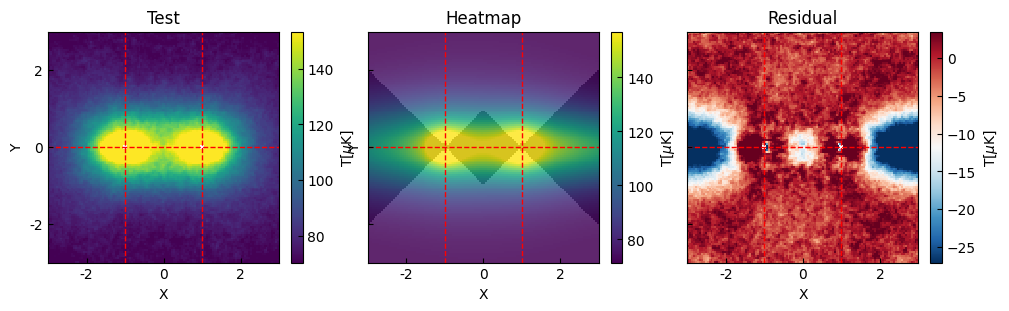

In [39]:
title = ['Test', 'Fitted', 'Residual']
axes =  plot_stack_fit_res(data_list_sector, title=title, fit_mask=mask_sector)
plot_axlines(ax=axes, vl=[40, 80], hl=[60])

<Axes: title={'center': 'Error Map'}, xlabel='X', ylabel='Y'>

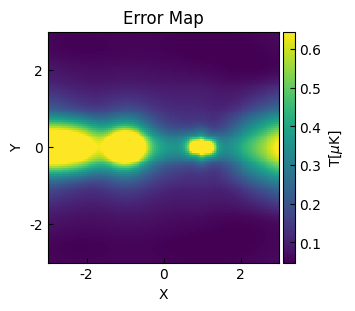

In [40]:
error_map = cov_to_err_map(fit_model, fit_info, *coord)
plot_heatmap(error_map, title='Error Map') 

# with mask square

<Axes: title={'center': 'Mask'}, xlabel='X', ylabel='Y'>

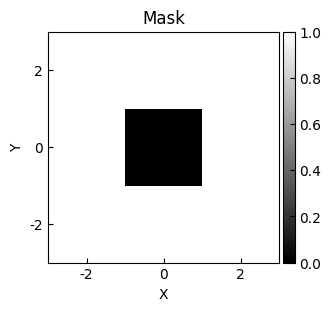

In [41]:
# mask_sq = ~get_mask_square(coord=coord)
mask_sq = ~get_mask_square(coord=coord, xlim=[-1, 1], ylim=[-1, 1])

plot_heatmap(mask_sq, title='Mask', cmap='gray', cbar_label='')

In [42]:
data_list_square, fit_model, fit_info = halofit(coord, data, model=model, mask=mask_sq, print_model=True)


Fitted double NFW model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2] + [3] + [4]
Components: 
    [0]: <NFW2D(amplitude=48.72157189, x_mean=-1., y_mean=0., r_s=0.71286673, ellipticity=0., theta=-115.71516182)>

    [1]: <NFW2D(amplitude=48.72332424, x_mean=1., y_mean=0., r_s=0.70305716, ellipticity=0., theta=86.08436012)>

    [2]: <Gaussian2D(amplitude=40.92470177, x_mean=-1., y_mean=0., x_stddev=1.2389784, y_stddev=1.00202308, theta=-12.72835463)>

    [3]: <Gaussian2D(amplitude=40.49837941, x_mean=1., y_mean=0., x_stddev=1.22513116, y_stddev=0.99063724, theta=-12.70716826)>

    [4]: <Const2D(amplitude=68.8581083)>
Parameters:
       amplitude_0    x_mean_0 y_mean_0 ...       theta_3          amplitude_4   
    ----------------- -------- -------- ... ------------------- -----------------
    48.72157189328687     -1.0      0.0 ... -12.707168255569474 68.85810830165384

Goodness of fit:
Chi-squared: 471270.932
Reduced chi-squ

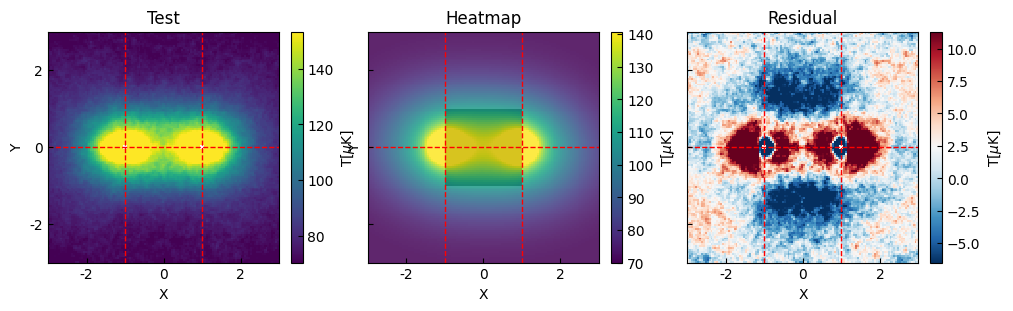

In [43]:
title = ['Test', 'Fitted', 'Residual']
axes =  plot_stack_fit_res(data_list_square, title=title, fit_mask=mask_sq)
# axes =  plot_stack_fit_res(data_list_square, title=title, fit_mask=mask_sq, vmax=[140,140, 20], vmin=[60, 60, -20])
plot_axlines(ax=axes, vl=[40, 80], hl=[60])

/home/dyliu/code/crafts_stack/src/crafts_stack/halo_fitting.py:212: RuntimeWarning: covariance is not symmetric positive-semidefinite.
  free_param_samples = rng.multivariate_normal(p_free_best, cov, size=n_samples)


<Axes: title={'center': 'Error Map'}, xlabel='X', ylabel='Y'>

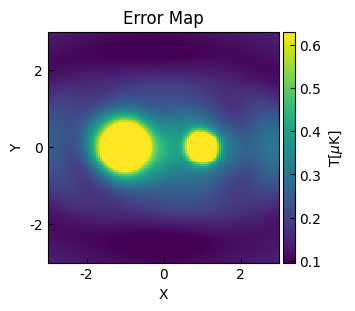

In [44]:
error_map = cov_to_err_map(fit_model, fit_info, *coord)
plot_heatmap(error_map, title='Error Map') 

# compare

(-100.0, 100.0)

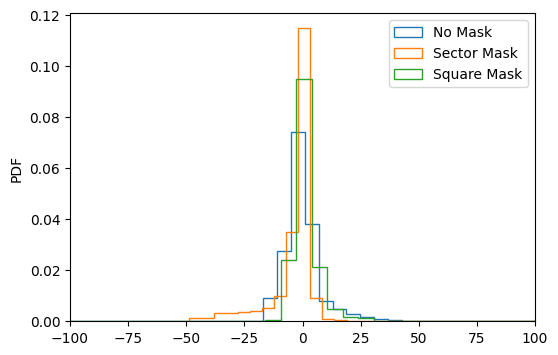

In [45]:
res_list = [data_list[-1].flatten(), data_list_sector[-1].flatten(), data_list_square[-1].flatten()]
labels = ['No Mask', 'Sector Mask', 'Square Mask']
# title = 'Residual comparison of %s model' %(name)
ax = plot_hist(res_list, label=labels, bins=100)
ax.set_xlim(-100, 100)

# profiles

In [55]:
stack_fit_res = data_list
# stack_fit_res = data_list_sector
# stack_fit_res = data_list_square

In [56]:
get_yprofile = lambda dlist, ind: [x[ind,:] for x in dlist]
get_xprofile = lambda dlist, ind: [x[:,ind] for x in dlist]

lines_list = [
    get_yprofile(stack_fit_res[:2], 60),
    get_xprofile(stack_fit_res[:2], 40),
    get_xprofile(stack_fit_res[:2], 80),
]
title_list = ['Y=0', 'X=-1', 'X=1']

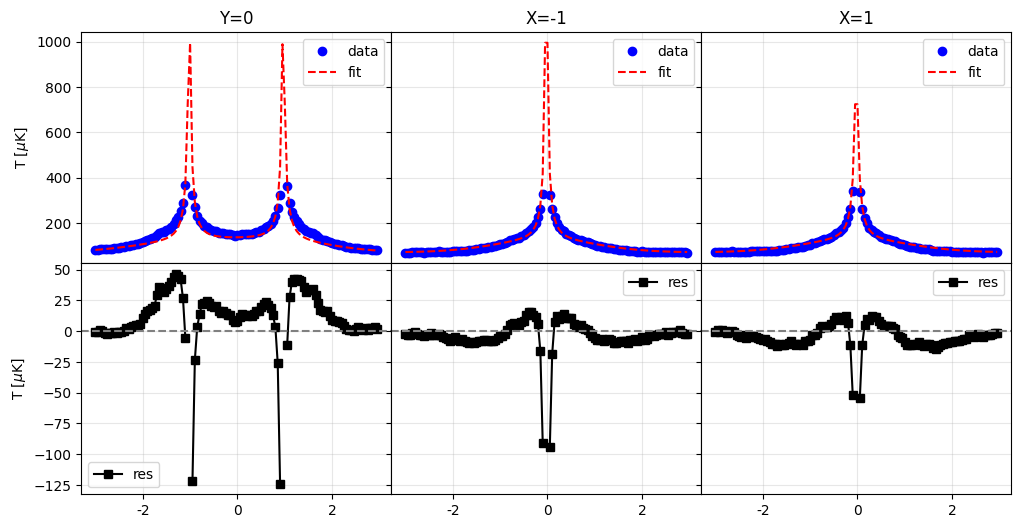

In [57]:
fig, axes = make_figure(2,3, figsize=(12,6), wspace=0., hspace=0.,aspect=None,sharex=True, sharey='row')

for i, lines in enumerate(lines_list):
    _axes = [axes[0,i], axes[1,i]]

    plot_line_diff(*lines, title=title_list[i], axes=_axes, labels=['data', 'fit', 'res'])

axes[0,0].set_ylabel(r'T [$\mu$K]')
axes[1,0].set_ylabel(r'T [$\mu$K]')
set_ticks(axes[1,0], share=False)

# estimate signal level

In [58]:
from mytools.estimate import get_signal_level
from mytools.plot import plot_profile_2c, plot_hist, make_figure
from mytools.data import read_h5

<Axes: title={'center': 'Weight'}, xlabel='X', ylabel='Y'>

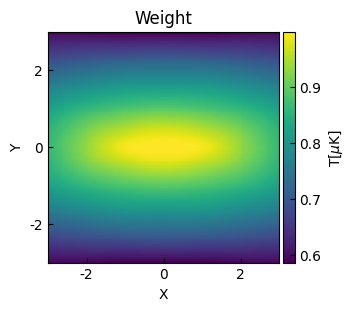

In [59]:
weight_path= '../data/pixcount_xsize3000_nfs10.h5'
pix_weights = read_h5(weight_path, 'tng_120k/weight')
# weights = read_h5(weight_path, 'crafts_122k/weight')
plot_heatmap(pix_weights, title='Weight', q=0.1)

Parameter names:
('amplitude_0', 'mean_0', 'stddev_0', 'amplitude_1')
Gauss fit parameters: [np.float64(21.768654306532667), np.float64(0.0), np.float64(0.4619119852792696), np.float64(-8.448405788720967)]
Gauss fit covariance: 
[[ 1.09099123e-01 -8.61786055e-04 -1.91671878e-02]
 [-8.61786055e-04  8.36930254e-05 -7.29721138e-04]
 [-1.91671878e-02 -7.29721138e-04  2.56801536e-02]]
0 points clipped during sigma clipping.

Goodness of fit:
Chi-squared: 1342.198
Reduced chi-squared: 11.472
RMS residual: 3.344

width: 0.4619119852792696
width_pix: 9


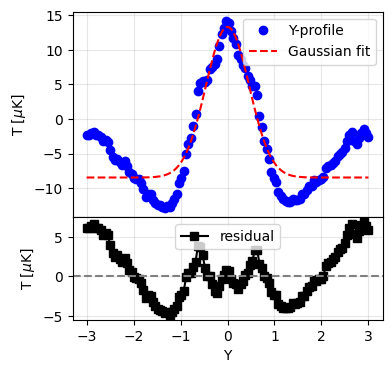

In [60]:
res = stack_fit_res[-1]
# bounds = (
#     [0, 0.1, -np.inf],
#     [np.inf, 0.7, np.inf],
# )
bounds = {
    "amplitude_0": (-np.inf, np.inf),  # amp > 0
    "stddev_0": (0.01, 0.7),  # sigma
}
lx, ly, clrb, params, cov = get_signal_level(res, weights=pix_weights, bounds=bounds, sigma_clip_sigma=3, show_fit=True);
# lx, ly, clrb, params, cov = get_signal_level(res, bounds=bounds, sigma_clip_sigma=5, weights=weight[:,50:70].mean(axis=1), show_fit=False);
# lx, ly, clrb, params, cov = get_signal_level(res);

array([<Axes: title={'center': 'Transverse-section profile'}, xlabel='Y', ylabel='$T$[$\\mu$K]'>,
       <Axes: title={'center': 'Lengthwise-section profile'}, xlabel='X'>],
      dtype=object)

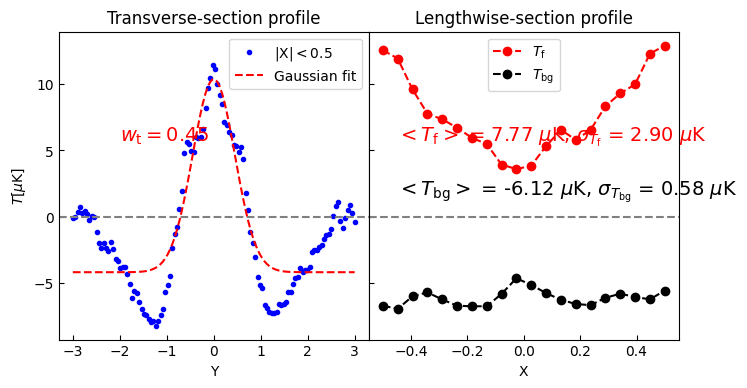

In [52]:
text_pos = [
    [-0.45, 0.5 * np.max(ly[0])], 
    [-0.45, -0.2* np.min(ly[0])], 
    [-2, 0.5 * np.max(ly[0])],
]
fig, axes = make_figure(1, 2, figsize=(8,4),wspace=0.,aspect=None,sharex=False)
plot_profile_2c(lx, ly, axes=axes, width=params[2], text_pos=text_pos)

<Axes: title={'center': 'Signal level'}, ylabel='PDF'>

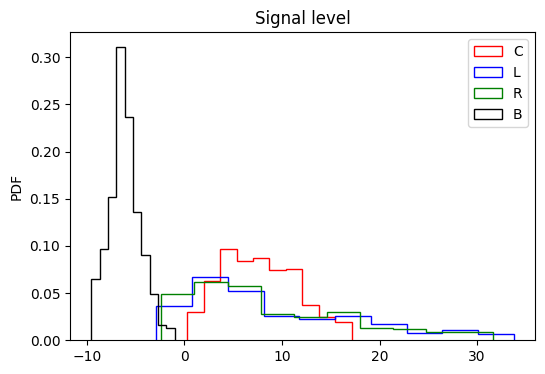

In [53]:
plot_hist(clrb, label=['C','L','R','B'], color=['r', 'b','g','k'], title='Signal level')